<a href="https://colab.research.google.com/github/mayankdotasm/tfr-bang/blob/feat%2Fstatistical-analysis/wine_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map({0: "Cultivar 0", 1: "Cultivar 1", 2: "Cultivar 2"})
df.to_csv("data/raw/wine_dataset.csv", index=False)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [4]:
df = pd.read_csv("data/raw/wine_dataset.csv")
features = ["alcohol", "malic_acid", "flavanoids", "color_intensity", "proline"]

# Descriptive & Inferential Analysis
desc = df.groupby("cultivar")[features].agg(["count", "mean", "std", "median"])
f_flav, p_flav = stats.f_oneway(
    df[df["target"] == 0]["flavanoids"],
    df[df["target"] == 1]["flavanoids"],
    df[df["target"] == 2]["flavanoids"],
)
t_alc, p_alc = stats.ttest_ind(
    df[df["target"] == 0]["alcohol"],
    df[df["target"] == 1]["alcohol"],
    equal_var=False,
)
r_val, p_corr = stats.pearsonr(df["alcohol"], df["proline"])

/tmp/ipykernel_3598/1288272818.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0, 0].boxplot([df[df["cultivar"] == c]["flavanoids"] for c in cultivars],


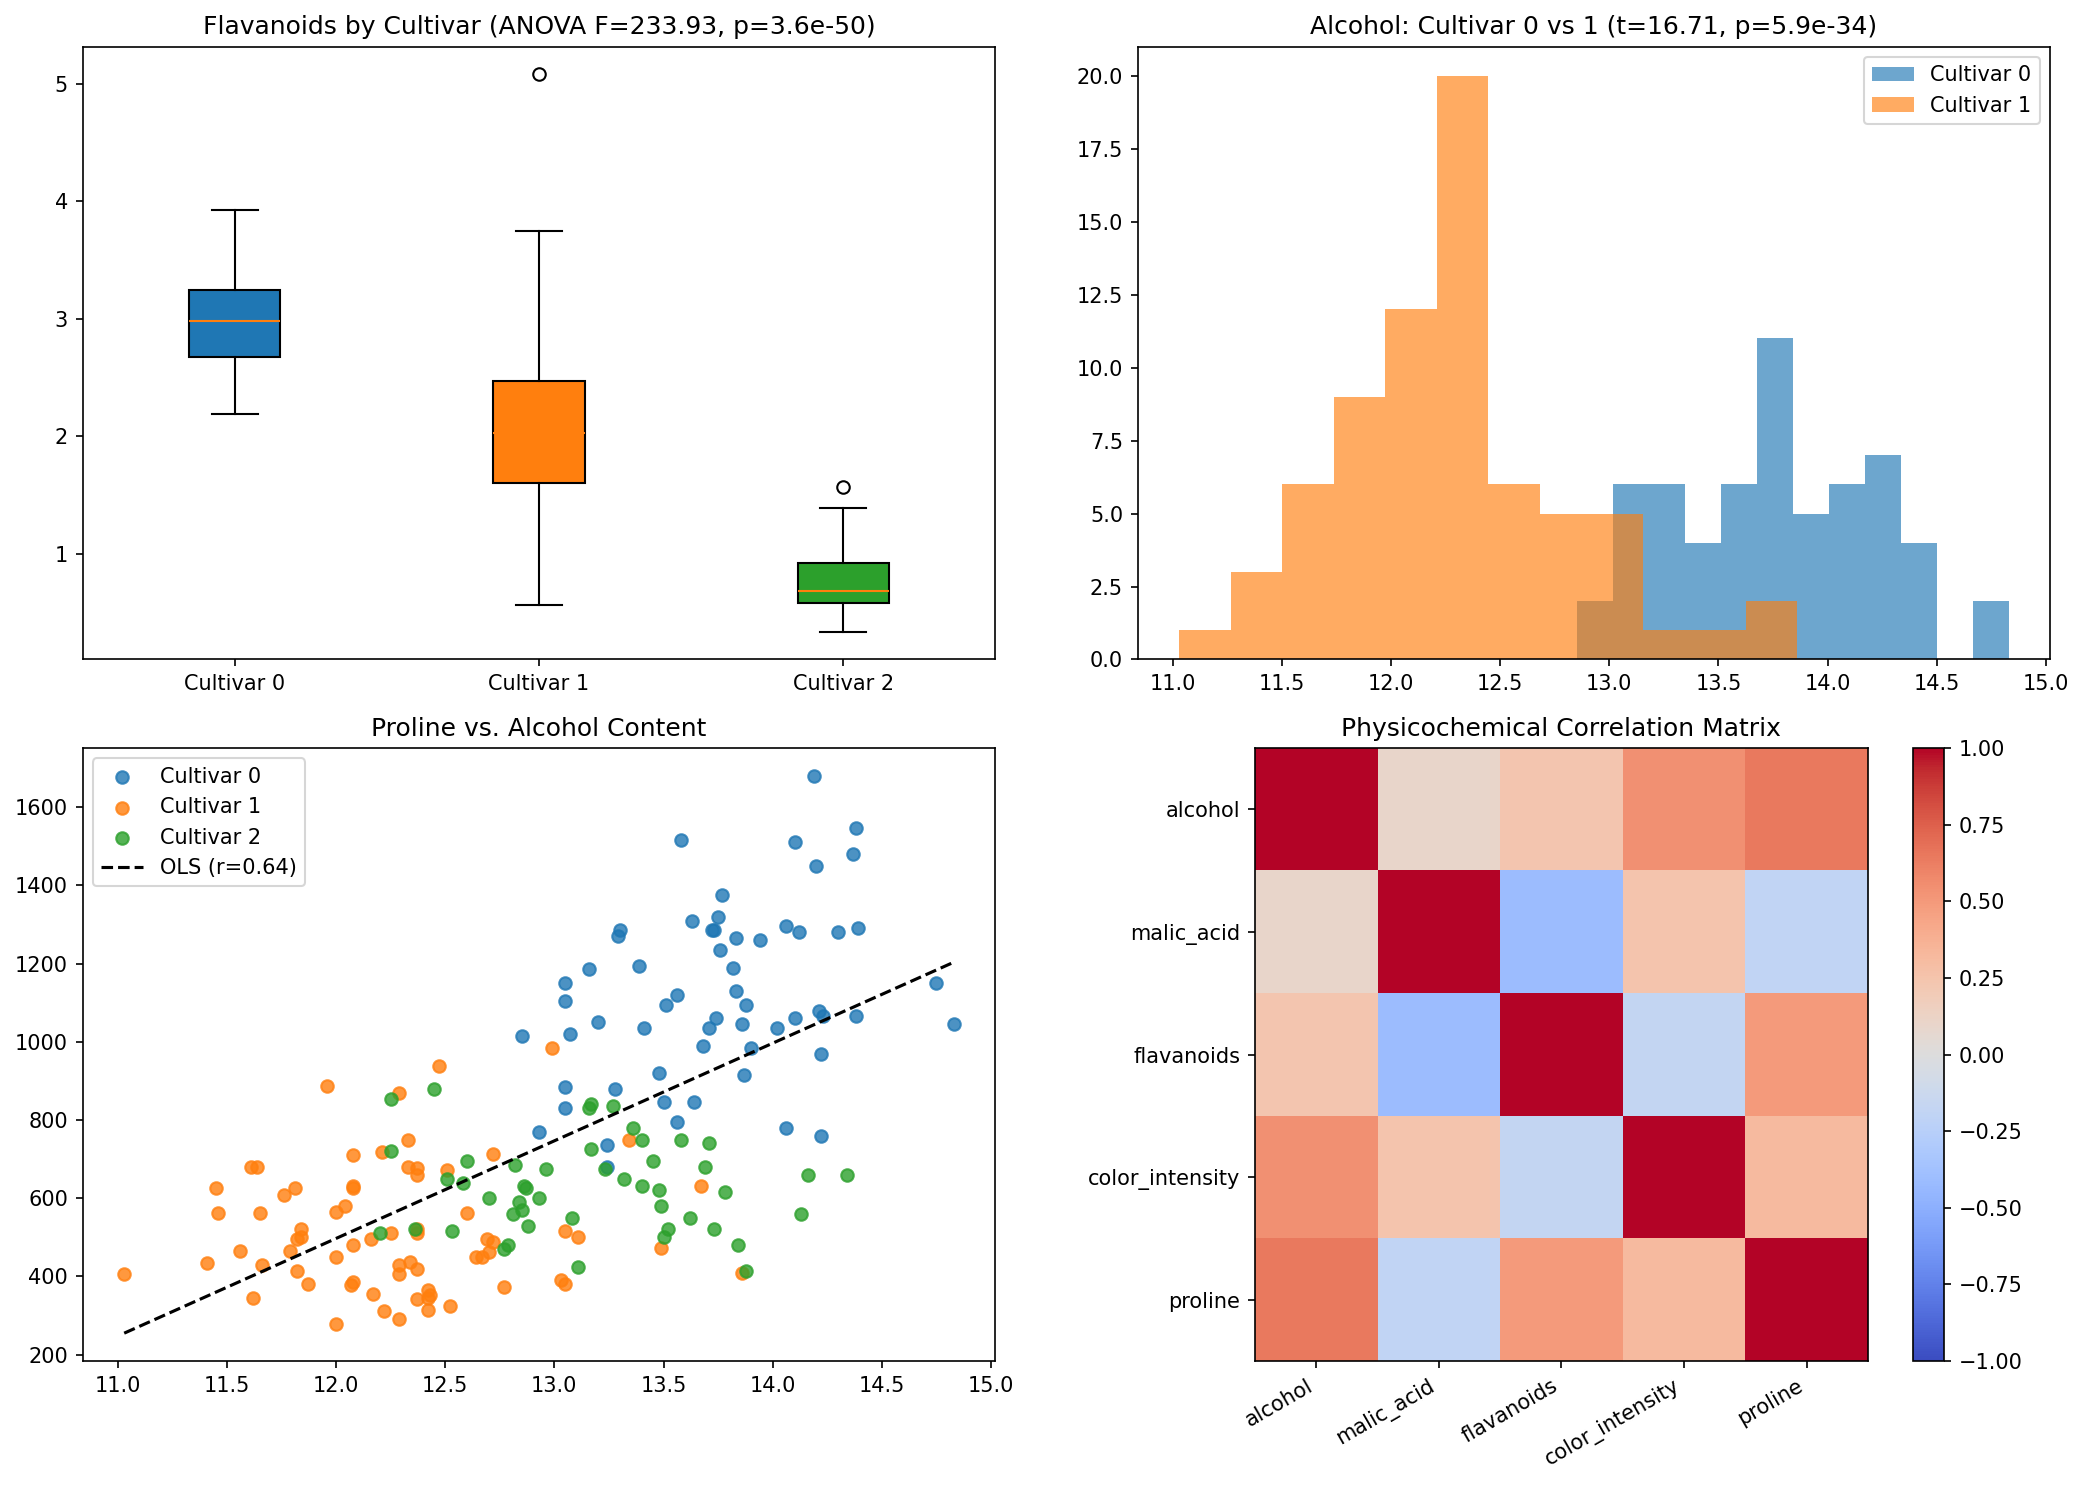

In [8]:
# Visual Analytics (Matplotlib)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
cultivars = ["Cultivar 0", "Cultivar 1", "Cultivar 2"]

# Panel 1: Boxplot
bp = axes[0, 0].boxplot([df[df["cultivar"] == c]["flavanoids"] for c in cultivars],
                        labels=cultivars, patch_artist=True)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
axes[0, 0].set_title(f"Flavanoids by Cultivar (ANOVA F={f_flav:.2f}, p={p_flav:.1e})")

# Panel 2: Histograms
for c, color in zip(["Cultivar 0", "Cultivar 1"], colors[:2]):
    axes[0, 1].hist(df[df["cultivar"] == c]["alcohol"], bins=12, alpha=0.65, label=c, color=color)
axes[0, 1].set_title(f"Alcohol: Cultivar 0 vs 1 (t={t_alc:.2f}, p={p_alc:.1e})")
axes[0, 1].legend()

# Panel 3: Scatter + OLS
for c, color in zip(cultivars, colors):
    sub = df[df["cultivar"] == c]
    axes[1, 0].scatter(sub["alcohol"], sub["proline"], label=c, color=color, alpha=0.8)
m, b = np.polyfit(df["alcohol"], df["proline"], 1)
x_vals = np.linspace(df["alcohol"].min(), df["alcohol"].max(), 100)
axes[1, 0].plot(x_vals, m * x_vals + b, "k--", label=f"OLS (r={r_val:.2f})")
axes[1, 0].set_title("Proline vs. Alcohol Content")
axes[1, 0].legend()

# Panel 4: Correlation Heatmap
corr = df[features].corr().values
im = axes[1, 1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1, 1].set_xticks(range(len(features)))
axes[1, 1].set_yticks(range(len(features)))
axes[1, 1].set_xticklabels(features, rotation=30, ha="right")
axes[1, 1].set_yticklabels(features)
fig.colorbar(im, ax=axes[1, 1])
axes[1, 1].set_title("Physicochemical Correlation Matrix")

plt.tight_layout()
plt.savefig("reports/figures/wine_statistical_analysis.png", dpi=500)